# TP 1 Transformer -> Du texte brut au premier modèle bigramme

Paul Pitiot, ING 3 Option IA Groupe B

## Objectif retenu

Passer du texte brut à des prédictions supervisées, puis entraîner une table qui prédit le caractère suivant (modèle bigramme) sur Tiny Shakespeare. Étapes du sujet : 1 télécharger et explorer, 2 `encode` et `decode`, 3 contextes et cibles, 4 mini-batch, 5 modèle bigramme, 6 générer, 7 entraîner.

`texte → entiers → (B, T) → logits (B, T, C) → loss → texte généré`

Livrable : un notebook exécuté de haut en bas, deux générations (avant et après entraînement). Les graines sont fixées ; `input.txt` est téléchargé s'il manque.

## 0. Environnement et config

Imports et graine fixée à 1337, comme dans le sujet.

In [1]:
import math
import os
from urllib.request import urlretrieve

import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

torch.manual_seed(1337)
print(torch.__version__)

2.14.0


## 1. Étape 1 : télécharger et explorer le corpus

Tiny Shakespeare, environ 1 million de caractères : le modèle reçoit une longue suite de caractères, pas des phrases.

In [2]:
url = ("https://raw.githubusercontent.com/karpathy/"
       "char-rnn/master/data/tinyshakespeare/input.txt")
if not os.path.exists("input.txt"):
    urlretrieve(url, "input.txt")

with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()

print(len(text))
print(text[:1000])

1115394
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for bread, not in thirst for re

**Questions**

- Quelle est l'unité d'un token ? Pourquoi `encoding="utf-8"` ? Le fichier est-il déjà séparé en exemples ?

Réponses :

- Un token est un caractère.
- UTF-8 est l'encodage qui transforme les octets du fichier en caractères.
- Non, le fichier n'est pas séparé en exemples : `text` est une seule chaîne, sans entrée ni cible, et le découpage se fait à l'étape 3.

> *Commentaire - 1 :* le corpus compte 1 115 394 caractères. Les retours à la ligne et les majuscules structurent le texte en pièce : un nom de personnage en majuscules suivi de `:`, puis ses vers.

## 2. Étape 2 : passer des caractères aux entiers

Vocabulaire = caractères distincts triés ; `stoi` et `itos` doivent être inverses l'un de l'autre.

In [3]:
chars = sorted(list(set(text)))
vocab_size = len(chars)
print(vocab_size)
print("".join(chars))

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join([itos[i] for i in ids])

message = "hii there"
print(encode(message))
print(decode(encode(message)))

65

 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
[46, 47, 47, 1, 58, 46, 43, 56, 43]
hii there


**Questions**

- Pourquoi trier `chars` ? Que garantit `decode(encode(message)) == message` ?

Réponses :

- On trie `chars` pour obtenir un ordre déterministe : les indices sont les mêmes à chaque exécution.
- Ce test garantit que `stoi` et `itos` sont inverses : encoder puis décoder redonne exactement le texte.

> *Commentaire - 2 :* le vocabulaire compte 65 caractères distincts. `"hii there"` devient `[46, 47, 47, 1, 58, 46, 43, 56, 43]` et le décodage redonne le message. Un identifiant n'a pas de sens en soi : il désigne une ligne dans une table, d'où des tokens entiers.

## 3. Étape 3 : former contextes et cibles

Split 90 / 10 sans mélange. Pour un bloc de `T + 1` caractères, `x` est formé des `T` premiers et `y` des mêmes décalés de 1 : chaque position prédit le caractère suivant.

In [4]:
data = torch.tensor(encode(text), dtype=torch.long)
print(data.shape, data.dtype)
print(data[:100])

n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]
print(len(train_data), len(val_data))
assert len(train_data) + len(val_data) == len(data)

torch.Size([1115394]) torch.int64
tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56, 58, 46, 43, 56,  6,  1, 46, 43, 39, 56,  1, 51, 43,  1,
        57, 54, 43, 39, 49,  8,  0,  0, 13, 50, 50, 10,  0, 31, 54, 43, 39, 49,
         6,  1, 57, 54, 43, 39, 49,  8,  0,  0, 18, 47, 56, 57, 58,  1, 15, 47,
        58, 47, 64, 43, 52, 10,  0, 37, 53, 59])
1003854 111540


In [5]:
block_size = 8

x = train_data[:block_size]
y = train_data[1:block_size + 1]

for t in range(block_size):
    context = x[:t + 1]
    target = y[t]
    print(context, "->", target)

tensor([18]) -> tensor(47)
tensor([18, 47]) -> tensor(56)
tensor([18, 47, 56]) -> tensor(57)
tensor([18, 47, 56, 57]) -> tensor(58)
tensor([18, 47, 56, 57, 58]) -> tensor(1)
tensor([18, 47, 56, 57, 58,  1]) -> tensor(15)
tensor([18, 47, 56, 57, 58,  1, 15]) -> tensor(47)
tensor([18, 47, 56, 57, 58,  1, 15, 47]) -> tensor(58)


**Questions**

- Combien de prédictions produit ce bloc ? Pourquoi ne pas mélanger train et validation ? Pour `t = 3`, quels sont le contexte et la cible ?

Réponses :

- Ce bloc produit 8 prédictions (`block_size = 8`), une par position.
- On ne mélange pas train et validation pour mesurer la généralisation sur des données jamais vues : un mélange fausserait la loss de validation.
- Pour `t = 3`, le contexte est `x[:4]` et la cible est `y[3]`, le 5e caractère.

> *Commentaire - 3 :* le train compte 1 003 854 caractères et la validation 111 540. Chaque ligne affichée est une paire contexte → cible, du contexte de 1 caractère à celui de 8.

## 4. Étape 4 : échantillonner un mini-batch

`B` séquences indépendantes de `T` caractères tirées au hasard : une ligne est une séquence, une colonne une position dans le temps.

In [6]:
batch_size = 4
block_size = 8


def get_batch(split):
    source = train_data if split == "train" else val_data
    starts = torch.randint(len(source) - block_size, (batch_size,))
    x = torch.stack([source[i : i + block_size] for i in starts])
    y = torch.stack([source[i + 1 : i + block_size + 1] for i in starts])
    return x, y


xb, yb = get_batch("train")
print(xb.shape, yb.shape)
print(xb)
print(yb)

torch.Size([4, 8]) torch.Size([4, 8])
tensor([[24, 43, 58,  5, 57,  1, 46, 43],
        [44, 53, 56,  1, 58, 46, 39, 58],
        [52, 58,  1, 58, 46, 39, 58,  1],
        [25, 17, 27, 10,  0, 21,  1, 54]])
tensor([[43, 58,  5, 57,  1, 46, 43, 39],
        [53, 56,  1, 58, 46, 39, 58,  1],
        [58,  1, 58, 46, 39, 58,  1, 46],
        [17, 27, 10,  0, 21,  1, 54, 39]])


In [7]:
# vérif : on retrouve les paires contexte -> cible de la partie 3, B fois
assert (xb[:, 1:] == yb[:, :-1]).all()  # y = x décalé d'une position
for b in range(batch_size):
    for t in range(block_size):
        print(xb[b, :t + 1].tolist(), "->", yb[b, t].item())
    print()

[24] -> 43
[24, 43] -> 58
[24, 43, 58] -> 5
[24, 43, 58, 5] -> 57
[24, 43, 58, 5, 57] -> 1
[24, 43, 58, 5, 57, 1] -> 46
[24, 43, 58, 5, 57, 1, 46] -> 43
[24, 43, 58, 5, 57, 1, 46, 43] -> 39

[44] -> 53
[44, 53] -> 56
[44, 53, 56] -> 1
[44, 53, 56, 1] -> 58
[44, 53, 56, 1, 58] -> 46
[44, 53, 56, 1, 58, 46] -> 39
[44, 53, 56, 1, 58, 46, 39] -> 58
[44, 53, 56, 1, 58, 46, 39, 58] -> 1

[52] -> 58
[52, 58] -> 1
[52, 58, 1] -> 58
[52, 58, 1, 58] -> 46
[52, 58, 1, 58, 46] -> 39
[52, 58, 1, 58, 46, 39] -> 58
[52, 58, 1, 58, 46, 39, 58] -> 1
[52, 58, 1, 58, 46, 39, 58, 1] -> 46

[25] -> 17
[25, 17] -> 27
[25, 17, 27] -> 10
[25, 17, 27, 10] -> 0
[25, 17, 27, 10, 0] -> 21
[25, 17, 27, 10, 0, 21] -> 1
[25, 17, 27, 10, 0, 21, 1] -> 54
[25, 17, 27, 10, 0, 21, 1, 54] -> 39



**Questions**

- Pourquoi retirer `block_size` à la borne de tirage ? Que changerait `B = 32` ? Que changerait `T = 64` ?

Réponses :

- On retire `block_size` parce que `y` sortirait du tenseur en fin de séquence sinon : `randint` s'arrête à `len - block_size - 1`.
- Avec `B = 32`, un batch donne 256 prédictions au lieu de 32 : le gradient est moins bruité et chaque étape coûte plus de calcul.
- Avec `T = 64`, un batch donne 2 048 prédictions. Le contexte plus long n'apporte rien au bigramme, seul le nombre de prédictions change (mesuré en partie 9).

> *Commentaire - 4 :* `xb` et `yb` ont la forme `(4, 8)` et `y` est `x` décalé d'une position (`assert`). Un batch donne bien `B × T = 32` paires contexte → cible.

## 5. Étape 5 : une table produit les logits

Une table `C × C` (`C = 65`) : la ligne d'un caractère contient les scores (logits) des caractères suivants. `(B, T)` indices → `(B, T, C)` logits ; la loss `F.cross_entropy` applique softmax puis `-log P(cible)`, moyennée sur les `B·T` positions.

In [8]:
class BigramLanguageModel(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        logits = self.token_embedding_table(idx)
        # idx: (B,T) -> logits: (B, T, C)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B * T, C)
            targets = targets.view(B * T)
            loss = F.cross_entropy(logits, targets)
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        # idx: (B, T)
        for _ in range(max_new_tokens):
            logits, _ = self(idx)
            logits = logits[:, -1, :]                           # (B, C)
            probs = F.softmax(logits, dim=-1)                   # (B, C)
            idx_next = torch.multinomial(probs, num_samples=1)  # (B, 1)
            idx = torch.cat((idx, idx_next), dim=1)             # (B, T+1)
        return idx


model = BigramLanguageModel(vocab_size)
logits, loss = model(xb, yb)
print(logits.shape)  # (B*T, C) : aplati pour la loss
print(loss.item())

torch.Size([32, 65])
5.036386013031006


In [9]:
@torch.no_grad()
def estimate_loss(model, split, n_batches=200):
    model.eval()
    out = torch.zeros(n_batches)
    for k in range(n_batches):
        xb, yb = get_batch(split)
        _, loss = model(xb, yb)
        out[k] = loss.item()
    model.train()
    return out.mean().item()


# sanity checks
print("paramètres :", sum(p.numel() for p in model.parameters()), "=", vocab_size**2)
print("loss modèle uniforme :", math.log(vocab_size))
print("loss du batch (init par défaut) :", loss.item())
print("loss moyenne sur 200 batchs (init par défaut, N(0, 1)) :", estimate_loss(model, "val"))

model_petite_init = BigramLanguageModel(vocab_size)
nn.init.normal_(model_petite_init.token_embedding_table.weight, std=0.02)
print("loss moyenne sur 200 batchs (init std = 0.02) :", estimate_loss(model_petite_init, "val"))

somme_probas = F.softmax(logits[0], dim=-1).sum().item()
print("somme des probas d'une ligne :", somme_probas)
assert abs(somme_probas - 1) < 1e-5

paramètres : 4225 = 4225
loss modèle uniforme : 4.174387269895637
loss du batch (init par défaut) : 5.036386013031006
loss moyenne sur 200 batchs (init par défaut, N(0, 1)) : 4.638201713562012
loss moyenne sur 200 batchs (init std = 0.02) : 4.1752519607543945
somme des probas d'une ligne : 1.0


**Questions**

- Pourquoi `C × C` ici ? Où retrouvera-t-on `d_emb` et `lm_head` au TP 4 ?

Réponses :

- La table est `C × C` parce que chaque caractère (ligne) porte un score pour chacun des 65 caractères suivants possibles (colonne).
- Au TP 4, `d_emb` devient `n_embd = 64` : `token_embedding_table` est de forme `(65, 64)` et `lm_head` est un `nn.Linear(64, 65)`, deux couches séparées.

> *Commentaire - 5 :* le modèle a 4 225 paramètres (`65 × 65`) et chaque ligne de probabilités somme à 1 grâce à softmax. La loss initiale vaut 4,64 en moyenne (5,04 sur le premier batch) pour `ln(65) = 4,17`, parce que les logits `N(0, 1)` ne sont pas égaux. Avec `std = 0,02`, elle vaut 4,175.

## 6. Étape 6 : générer avec les poids aléatoires

Contexte de départ : un seul token (indice 0, le saut de ligne). Je garde le texte pour comparer après entraînement.

In [10]:
idx = torch.zeros((1, 1), dtype=torch.long)
texte_avant = decode(model.generate(idx, max_new_tokens=300)[0].tolist())
print(texte_avant)


BfBpBhxxx'VgB$yfpFGm:kDVDc-DSnzk?oisqpXAtzLIJnz&$UCL:bbPUsEO!qDRCFdu'ItpC.?otVyjv!rrzYUg;3ugqThOFh bep-EFWtY$VPy;ydN'3vyw,yVXcniEzydSq$nLbBPOhB.wgkNubDw3mrcvVQciLGBP3ptkAvwFGr;Bd U IFQ baBm b-swl-Tsp
QXV$eJI!LBwHQPbD-b.Qhnq&PLiN
uag;l?oy lBf3b.Y3pJGTherzLLa bDexpkqCAkwEFbbHAYDmSQ!d:HEYQXUE?bxWF
lP b


> *Commentaire - 6 :* avec des poids aléatoires, le texte est un charabia, sans mot ni structure.

## 7. Étape 7 : entraîner la table

Boucle du cours : batch, loss, `backward`, `step`, avec remise à zéro des gradients. `AdamW` à `lr = 1e-3` comme dans le sujet : 100 étapes, puis 1 000 de plus.

In [11]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)

batch_size = 32
losses = []

for step in range(100):
    xb, yb = get_batch("train")
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

print(loss.item())

4.533756732940674


In [12]:
# même génération qu'en 6, après 100 étapes
idx = torch.zeros((1, 1), dtype=torch.long)
texte_apres_100 = decode(model.generate(idx, max_new_tokens=300)[0].tolist())
print(texte_apres_100)


PU 'ZEQTGdhfCfJHQU?::XQSl;tKX'?eXNNhd
FkNk
t&!E?A3tqzL-MIREFgwA!s:yTHJqWELmqUENZZEecu$kn-Mn3f:RkwNGET 
X3m&mFhVDRpWXeFlq'iclcing;
:LmQ:
3!!qdwV
kN NNITyEq$wkChvVK&$?:pECAZENingk?oCgAsfZFs33;ni-SzXM.ucmdvVefJjNTk;NTuhU3ReFGEzrFGJhbBfv$n
BfcisDiayfJsq$HNbBk;,T ydVQYjxxn$Gcmw Wo&r jW ZcFTZaROCdUnmAWtJs


Variante : 1 000 étapes de plus sur le même modèle.

In [13]:
for step in range(1000):
    xb, yb = get_batch("train")
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

print(loss.item())

idx = torch.zeros((1, 1), dtype=torch.long)
texte_apres_1100 = decode(model.generate(idx, max_new_tokens=300)[0].tolist())
print(texte_apres_1100)

3.720097064971924

wld zyMGugkAYusuQTHyiuzyF:'D.uCo&mVRfJ3fvitastw'vaRRsq&$kD ruzWreFzYllbjsprBUCo
'tvN'Rrzk!qymv3b-HW,eX'$TFS.QCROF ILCKlUnitP zk-mZLEuV
XMxWn:hOyerZETH
AW,OptpKXXxM$oa$JMDKnPVQL;V,ONxprzyoe:Zoe!WA&dsfUcisli!LC;GunJPLX
lIZ
OYerQk
H!;G?
UZN:qph afy!Ea wjtw:.mcLR cZ
wovenAYLEPVn:umys;ODXYO;raUBOARKp?qEz


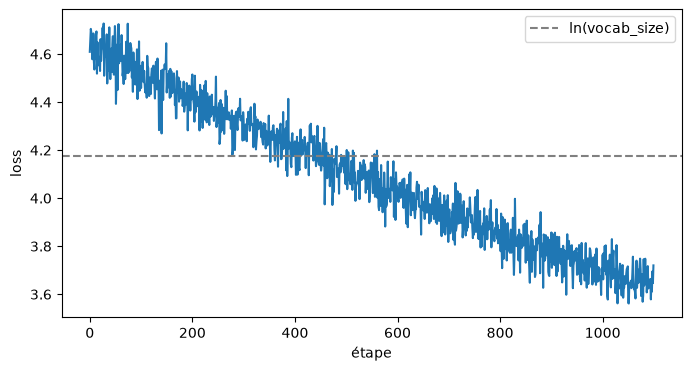

In [14]:
plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.axhline(math.log(vocab_size), linestyle="--", color="gray", label="ln(vocab_size)")
plt.xlabel("étape")
plt.ylabel("loss")
plt.legend()
plt.show()

In [15]:
# loss moyenne sur train et val
print("train :", estimate_loss(model, "train"))
print("val   :", estimate_loss(model, "val"))

train : 3.6236984729766846
val   : 3.634483575820923


In [16]:
# plafond du bigramme : la meilleure table possible est donnée par les fréquences de bigrammes du train
# (+1 sur chaque case : 187 bigrammes de val n'apparaissent jamais dans le train, sans lissage la loss vaudrait inf)
counts = torch.ones(vocab_size, vocab_size)
counts.index_put_((train_data[:-1], train_data[1:]), torch.ones(len(train_data) - 1), accumulate=True)
p_bigramme = counts / counts.sum(dim=1, keepdim=True)


def loss_comptage(source):
    return -torch.log(p_bigramme[source[:-1], source[1:]]).mean().item()


print("table par comptage, train :", loss_comptage(train_data))
print("table par comptage, val   :", loss_comptage(val_data))

table par comptage, train : 2.45457124710083
table par comptage, val   : 2.481889247894287


In [17]:
# ce que la table a appris : caractères suivants les plus probables pour quelques caractères
with torch.no_grad():
    for ch in ["q", "t", " ", "\n", "."]:
        probs = F.softmax(model.token_embedding_table.weight[stoi[ch]], dim=-1)
        top = torch.topk(probs, 5)
        print(repr(ch), [(itos[i.item()], round(p.item(), 2)) for p, i in zip(top.values, top.indices)])

'q' [('$', 0.16), ('!', 0.07), ('p', 0.05), ('C', 0.03), ('&', 0.03)]
't' [('o', 0.06), ('p', 0.05), ('e', 0.05), ('h', 0.05), ("'", 0.04)]
' ' [('b', 0.09), ('m', 0.05), ('a', 0.04), ('y', 0.04), ('z', 0.04)]
'\n' [('l', 0.08), ('O', 0.07), ('\n', 0.05), ('F', 0.05), ('N', 0.04)]
'.' [('.', 0.07), ('e', 0.06), ('B', 0.05), ('u', 0.04), ('O', 0.04)]


> *Commentaire - 7 :* à `lr = 1e-3`, la loss du dernier batch passe de 4,53 (100 étapes) à 3,72 (1 100 étapes) et la courbe descend encore. La meilleure table de bigrammes (comptage sur le train) donne 2,455 en train et 2,482 en validation.

## 8. Variante : learning rate

À `lr = 1e-3`, la loss (3,6) est encore loin du plancher de la table par comptage (2,5). Même procédure (100 puis 1 000 étapes), modèle neuf, avec `lr = 1e-2`.

In [18]:
torch.manual_seed(1337)
model_lr = BigramLanguageModel(vocab_size)
optimizer_lr = torch.optim.AdamW(model_lr.parameters(), lr=1e-2)
losses_lr = []

for step in range(1100):
    xb, yb = get_batch("train")
    _, loss = model_lr(xb, yb)
    optimizer_lr.zero_grad(set_to_none=True)
    loss.backward()
    optimizer_lr.step()
    losses_lr.append(loss.item())

print("train :", estimate_loss(model_lr, "train"))
print("val   :", estimate_loss(model_lr, "val"))

idx = torch.zeros((1, 1), dtype=torch.long)
print(decode(model_lr.generate(idx, max_new_tokens=300)[0].tolist()))

train : 2.4816362857818604
val   : 2.5096447467803955


Ycedm ouscape n
LAnde, hiofingis aned, mbbedeatFOL:
.
O:I mind:
Whofive hind!
CHARooxcerer me h
What'dotoreng tavecas aletl-s.
inol nke tk!klf Bl cVe
Gougan geay ad it feeobureizl ce wio branthir henet?
Boulli:
A pan; q--llenQxfl, ak t, d
h hand styof the he thinde y seag t thitho t y imer whTOWhed


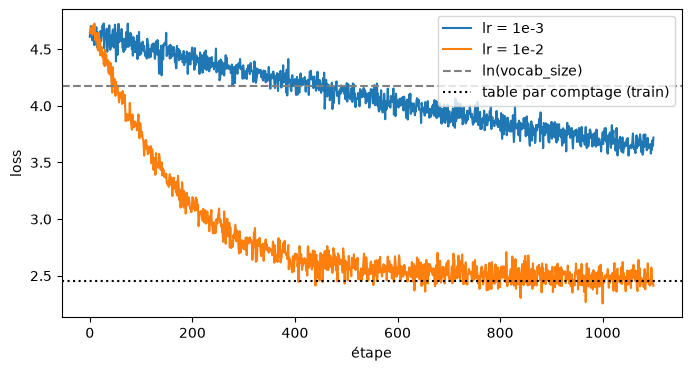

In [19]:
plt.figure(figsize=(8, 4))
plt.plot(losses, label="lr = 1e-3")
plt.plot(losses_lr, label="lr = 1e-2")
plt.axhline(math.log(vocab_size), linestyle="--", color="gray", label="ln(vocab_size)")
plt.axhline(loss_comptage(train_data), linestyle=":", color="black", label="table par comptage (train)")
plt.xlabel("étape")
plt.ylabel("loss")
plt.legend()
plt.show()

In [20]:
# même lecture de la table qu'en 7, pour le modèle à lr = 1e-2
with torch.no_grad():
    for ch in ["q", "t", " ", "\n", "."]:
        probs = F.softmax(model_lr.token_embedding_table.weight[stoi[ch]], dim=-1)
        top = torch.topk(probs, 5)
        print(repr(ch), [(itos[i.item()], round(p.item(), 2)) for p, i in zip(top.values, top.indices)])

'q' [('u', 0.67), ('-', 0.05), (',', 0.02), ('f', 0.02), ('H', 0.02)]
't' [('h', 0.33), (' ', 0.24), ('o', 0.08), ('e', 0.06), ('i', 0.04)]
' ' [('t', 0.14), ('a', 0.08), ('h', 0.07), ('s', 0.07), ('w', 0.06)]
'\n' [('\n', 0.17), ('T', 0.1), ('A', 0.09), ('W', 0.07), ('I', 0.06)]
'.' [('\n', 0.84), (' ', 0.11), ('?', 0.0), ('i', 0.0), ('y', 0.0)]


> *Commentaire - 8 :* avec `lr = 1e-2`, la loss vaut 2,48 en train et 2,51 en validation, proche du plancher du comptage. Le texte contient des mots courts (`the`, `he`, `hand`, `mind`) et des noms suivis de `:` (`Boulli:`). La table a appris `q → u` (0,67) et `. → saut de ligne` (0,84), alors qu'à `1e-3` ses lignes sont presque plates.

## 9. Variante : effet de `B` et de `T`

Trois modèles neufs (même graine), 300 étapes chacun, avec `(B, T) = (4, 8)`, `(32, 8)` puis `(32, 64)`. La loss de validation est toujours mesurée sur `B = 32`, `T = 8`.

In [21]:
for B, T in [(4, 8), (32, 8), (32, 64)]:
    batch_size, block_size = B, T
    torch.manual_seed(0)
    m = BigramLanguageModel(vocab_size)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-2)
    pertes = []
    for step in range(300):
        xb, yb = get_batch("train")
        _, loss = m(xb, yb)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        pertes.append(loss.item())
    batch_size, block_size = 32, 8
    bruit = torch.tensor(pertes[-50:]).std().item()
    print(f"B={B:2d} T={T:2d} : {B * T:4d} prédictions/batch, écart-type de la loss (50 derniers batchs) {bruit:.3f}, val {estimate_loss(m, 'val'):.3f}")

B= 4 T= 8 :   32 prédictions/batch, écart-type de la loss (50 derniers batchs) 0.216, val 3.216


B=32 T= 8 :  256 prédictions/batch, écart-type de la loss (50 derniers batchs) 0.075, val 2.804


B=32 T=64 : 2048 prédictions/batch, écart-type de la loss (50 derniers batchs) 0.032, val 2.675


> *Commentaire - 9 :* de `(4, 8)` à `(32, 64)`, l'écart-type de la loss passe de 0,22 à 0,08 puis 0,03, et la loss de validation de 3,22 à 2,80 puis 2,68. Plus de prédictions par batch donnent un gradient moins bruité.

## 10. Bilan du TP 1

**Questions**

- Pourquoi ne garder que le dernier pas de temps pendant la génération ? Pourquoi aplatir `B × T` pour la loss ? Comparez la loss et le texte avant, après 100 puis après 1 000 étapes.

Réponses :

- On ne garde que le dernier pas de temps parce que le bigramme ne conditionne que sur le dernier caractère : seule cette prédiction sert à choisir le suivant.
- On aplatit `B × T` parce que `F.cross_entropy` attend des logits `(N, C)` et des cibles `(N,)` : avec `N = B·T`, elle calcule la moyenne de `-log P(cible)` du cours.
- À `lr = 1e-3`, la loss vaut 5,04 avant l'entraînement, 4,53 après 100 étapes et 3,72 après 1 100 (train 3,62, val 3,63). Le texte reste un charabia, avec quelques retours à la ligne puis un `:` derrière des majuscules.
- L'entraînement ne modifie que les 4 225 valeurs de `token_embedding_table`. La loss plafonne vers 2,5 parce que la prédiction ne dépend que du dernier caractère : l'attention du TP 2 doit dépasser ce plafond.

## 11. Consignes du sujet

| Consigne | Où |
|---|---|
| Étape 1 : télécharger et explorer, questions sur le token, `utf-8`, exemples | partie 1 |
| Étape 2 : `encode` et `decode`, questions `chars` trié et `decode(encode(m))` | partie 2 |
| Étape 3 : contextes, cibles, split train / validation, 3 questions | partie 3 |
| Étape 4 : `get_batch`, `B`, `T`, 3 questions | partie 4 |
| Étape 5 : modèle bigramme, logits en probabilités, `(B, T, C)`, 2 questions | partie 5 |
| Étape 6 : génération avant entraînement | partie 6 |
| Étape 7 : entraînement `AdamW`, génération après 100 puis 1 100 étapes | partie 7 |
| Variantes : learning rate, `B` et `T` | parties 8 et 9 |
| Bilan du TP 1 | partie 10 |
| Formes vérifiées à chaque étape | `assert` et formes affichées dans les cellules |